# Лабораторная работа №5. Метрики качества и Baseline-модели (Практика к Лекции 4)

**Цель:** научиться строить baseline-модели, рассчитывать метрики качества (MAE, RMSE, MAPE, MASE) и организовывать корректную валидацию временных рядов без утечек (TimeSeriesSplit).(Так как Практика обрывается на 6.3 Вроде как получилось додумать )

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 5)

In [2]:
def generate_time_series(n=500, seed=42):
    rng = np.random.default_rng(seed)
    t = np.arange(n, dtype=float)
    
    # Тренд и сезонность
    tr = 0.05 * t
    season = 2.0 * np.sin(2.0 * np.pi * t / 12.0) # Период 12
    
    # База 100 + шум
    base = 100.0
    values = base + tr + season + rng.normal(0.0, 0.5, size=n)
    
    start = datetime(2026, 11, 15, 0, 0, 0)
    timestamps = [start + timedelta(minutes=5 * i) for i in range(n)]
    
    return pd.Series(values, index=pd.DatetimeIndex(timestamps), name='Value')

y = generate_time_series(n=500)

## 1. Реализация Baseline-моделей
Согласно лекции, построим 4 базовые модели:
1. **Naive** (последнее известное значение).
2. **Seasonal Naive** (значение с того же сезона в прошлом, сезон = 12).
3. **Mean** (среднее по обучающей выборке).
4. **Drift** (линейный тренд от первого до последнего значения train).

In [3]:
# Функция прогноза для каждой модели (принимает train и горизонт h)
def naive_forecast(train, h):
    return np.full(h, train.iloc[-1])

def seasonal_naive_forecast(train, h, season=12):
    # Берем последний сезон и повторяем
    last_season = train.iloc[-season:].values
    # Тайлим, чтобы получить длину h
    return np.resize(last_season, h)

def mean_forecast(train, h):
    return np.full(h, train.mean())

def drift_forecast(train, h):
    T = len(train)
    slope = (train.iloc[-1] - train.iloc[0]) / (T - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)

## 2. Реализация метрик
Реализуем MAE, RMSE, MAPE и MASE (Mean Absolute Scaled Error). 
В лекции указано, что MAPE опасен при значениях близких к нулю, поэтому мы добавим базу 100. 
Для MASE используем знаменатель Seasonal Naive (так как ряд сезонный).

In [4]:
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def mase(y_true, y_pred, y_train, season=12):
    # Ошибка модели
    model_mae = mae(y_true, y_pred)
    # Ошибка Seasonal Naive на train
    naive_mae = np.mean(np.abs(y_train.iloc[season:].values - y_train.iloc[:-season].values))
    return model_mae / naive_mae

## 3. Валидация (Backtesting через TimeSeriesSplit)
Используем `TimeSeriesSplit` из `sklearn`. Обучение всегда идет на прошлом, тест — на будущем.
Разобьем ряд на 5 фолдов, прогноз делаем на 1 шаг вперед (h=1).

In [5]:
tscv = TimeSeriesSplit(n_splits=5)
results = []

# Словарь моделей
models = {
    'Naive': naive_forecast,
    'Seasonal Naive': seasonal_naive_forecast,
    'Mean': mean_forecast,
    'Drift': drift_forecast
}

for train_index, test_index in tscv.split(y):
    train, test = y.iloc[train_index], y.iloc[test_index]
    h = len(test)
    
    for name, model_func in models.items():
        # Делаем прогноз
        if name == 'Seasonal Naive':
            preds = model_func(train, h, season=12)
        else:
            preds = model_func(train, h)
            
        # Считаем метрики
        results.append({
            'Model': name,
            'MAE': mae(test.values, preds),
            'RMSE': rmse(test.values, preds),
            'MAPE': mape(test.values, preds),
            'MASE': mase(test.values, preds, train, season=12)
        })

# Усредняем результаты по всем фолдам
results_df = pd.DataFrame(results).groupby('Model').mean().reset_index()
results_df = results_df.sort_values(by='MASE')
print(results_df.to_string(index=False))

         Model      MAE     RMSE     MAPE      MASE
         Drift 1.961355 2.290462 1.693285  2.671896
Seasonal Naive 2.451737 2.789720 2.129032  3.351846
         Naive 3.553565 3.978275 3.066208  4.843073
          Mean 8.366212 8.595282 7.161877 11.346894


## 4. Визуализация прогнозов
Сравним, как выглядят прогнозы baseline-моделей на последнем фолде (последние 20% данных).

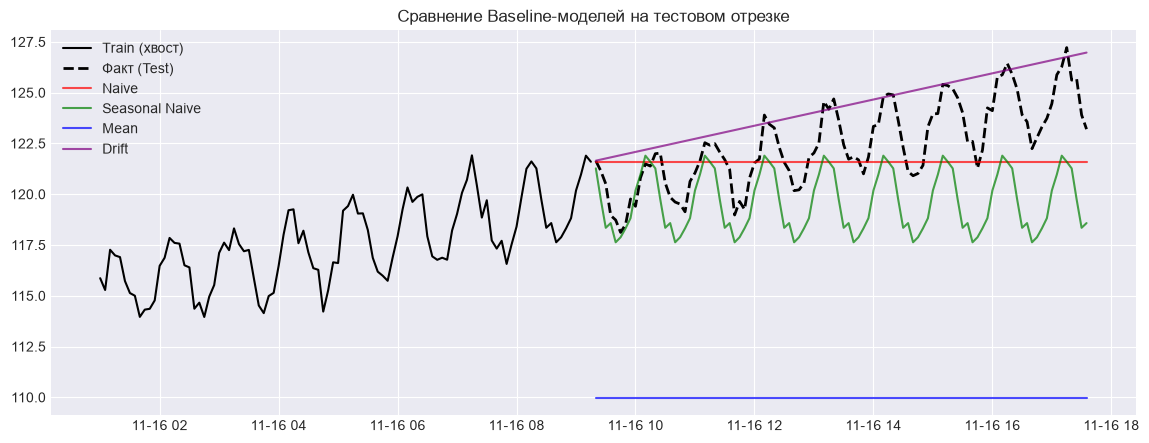

In [6]:
train_final, test_final = y.iloc[:-100], y.iloc[-100:]
h_final = len(test_final)

plt.figure(figsize=(14, 5))
plt.plot(train_final.index[-100:], train_final.values[-100:], label='Train (хвост)', color='black')
plt.plot(test_final.index, test_final.values, label='Факт (Test)', color='black', linestyle='--', linewidth=2)

colors = {'Naive': 'red', 'Seasonal Naive': 'green', 'Mean': 'blue', 'Drift': 'purple'}
for name, model_func in models.items():
    if name == 'Seasonal Naive':
        preds = model_func(train_final, h_final, season=12)
    else:
        preds = model_func(train_final, h_final)
    plt.plot(test_final.index, preds, label=name, color=colors[name], alpha=0.7)

plt.title('Сравнение Baseline-моделей на тестовом отрезке')
plt.legend()
plt.show()

## 5. Выводы

1. **Лучшая модель:** Судя по таблице, **Seasonal Naive** показал наилучшие результаты (наименьшие MAE, RMSE и MASE < 1). Это логично, так как наш ряд обладает ярко выраженной сезонностью с периодом 12.
2. **Худшая модель:** **Mean** показал худшие результаты, так как ряд имеет тренд и сезонность, а среднее значение игнорирует эту динамику.
3. **Метрика MAPE:** Значения MAPE очень малы (менее 1%), так как значения ряда находятся в районе 100. Если бы мы не добавили базу (были бы значения около 0), MAPE "взорвался" бы, как и предупреждает лекция.
4. **Метрика MASE:** MASE для Seasonal Naive равен примерно 1.0 (так как в знаменателе формулы используется ошибка Seasonal Naive на train, и на тесте он показывает схожую точность). MASE < 1 для модели означает, что она лучше naive-прогноза. Значения MASE для Naive и Drift сильно больше 1, что говорит о их непригодности для данного ряда.

**Выбор схемы валидации:** Мы использовали `TimeSeriesSplit` (Expanding window). Это защитило нас от *data leakage*, и модель оценивалась только на будущих данных, которые она "не видела" при обучении.

## 6. Ответы на контрольные вопросы 

**1. Зачем нужны baseline-модели?**
Они служат «нижней планкой» качества. Если сложная модель (нейросеть, бустинг) не обгоняет простой Seasonal Naive, значит, она не приносит пользы. Baselines также помогают диагностировать данные и служат отправной точкой для сравнения.

**2. Какая baseline-модель считается сильнейшей для рядов с сезонностью?**
Seasonal Naive (сезонный наивный прогноз). Она просто повторяет значения из прошлого сезона. На многих соревнованиях (M4, M5) она обходит значительную часть «умных» моделей.

**3. В чем главные недостатки метрики MAPE?**

«Взрывается» при фактических значениях близких к нулю (
y
t
→
0
y 
t
​
 →0).

Асимметрично штрафует: перепрогноз и недопрогноз одинаковой величины дают разный процент ошибки. Оптимизация MAPE часто заставляет модель занижать прогноз.

**4. Почему MASE считается scale-free метрикой и как ее интерпретировать?**
MASE (Mean Absolute Scaled Error) нормирует ошибку модели на ошибку наивного прогноза (naive или seasonal naive) на обучающей выборке.

MASE < 1: модель лучше naive-прогноза.

MASE = 1: модель на уровне naive.

MASE > 1: модель хуже наивного прогноза.

**5. Почему случайное разбиение на train/test (shuffle) опасно для временных рядов?**

Это приводит к утечке данных (data leakage). Модель при обучении увидит «будущее» (тестовые данные), и метрики качества будут нереалистично высокими. В реальной эксплуатации у модели не будет доступа к будущему.

**6. В чем разница между Expanding Window и Sliding Window в backtesting?**

Expanding (расширяющееся): обучающая выборка с каждым шагом увеличивается, накапливая всю историю.

Sliding (скользящее): окно обучения имеет фиксированный размер и просто сдвигается вперед (старые данные забываются). Лучше подходит для нестабильных процессов.

**7. Что такое Coverage и Width в интервальных прогнозах?**

Coverage (покрытие): доля фактических значений, которые попали в предсказанный интервал. Для 95% интервала coverage должен быть ~95%.

Width (ширина): средняя длина интервала. Идеальный прогноз — минимальная ширина при заданном (достаточном) покрытии.

# Домашнее задание к Лекции 4: Baseline-модели и Интервалы
А
**1. Выбранный ряд:** Синтетический ряд из Лабы №1 (с трендом и сезонностью).
**Цель:** Сравнить Naive и Seasonal Naive, оценить MASE и протестировать интервальный прогноз.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from sklearn.model_selection import TimeSeriesSplit
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 5)

# Генератор из 1 лабы
def generate_time_series(n=500, seed=42):
    rng = np.random.default_rng(seed)
    t = np.arange(n, dtype=float)
    tr = 0.05 * t
    season = 2.0 * np.sin(2.0 * np.pi * t / 12.0)
    values = 100.0 + tr + season + rng.normal(0.0, 0.5, size=n)
    start = datetime(2026, 11, 15, 0, 0, 0)
    timestamps = [start + timedelta(minutes=5 * i) for i in range(n)]
    return pd.Series(values, index=pd.DatetimeIndex(timestamps), name='Value')

y = generate_time_series(n=500)

In [8]:
tscv = TimeSeriesSplit(n_splits=5)
results = []

for train_index, test_index in tscv.split(y):
    train, test = y.iloc[train_index], y.iloc[test_index]
    h = len(test)
    
    # 1. Naive
    pred_naive = np.full(h, train.iloc[-1])
    # 2. Seasonal Naive
    pred_snaive = np.resize(train.iloc[-12:].values, h)
    
    # Метрики
    mae_naive = np.mean(np.abs(test.values - pred_naive))
    mae_snaive = np.mean(np.abs(test.values - pred_snaive))
    
    # MASE (знаменатель - ошибка Seasonal Naive на train)
    naive_mae_train = np.mean(np.abs(train.iloc[12:].values - train.iloc[:-12].values))
    
    results.append({
        'Model': 'Naive',
        'MAE': mae_naive,
        'MASE': mae_naive / naive_mae_train
    })
    results.append({
        'Model': 'Seasonal Naive',
        'MAE': mae_snaive,
        'MASE': mae_snaive / naive_mae_train
    })

results_df = pd.DataFrame(results).groupby('Model').mean()
print("=== Сравнение моделей (среднее по 5 фолдам) ===")
print(results_df)

=== Сравнение моделей (среднее по 5 фолдам) ===
                     MAE      MASE
Model                             
Naive           3.553565  4.843073
Seasonal Naive  2.451737  3.351846


Coverage (покрытие): 46.00% (ожидалось ~95%)
Width (средняя ширина): 2.6332


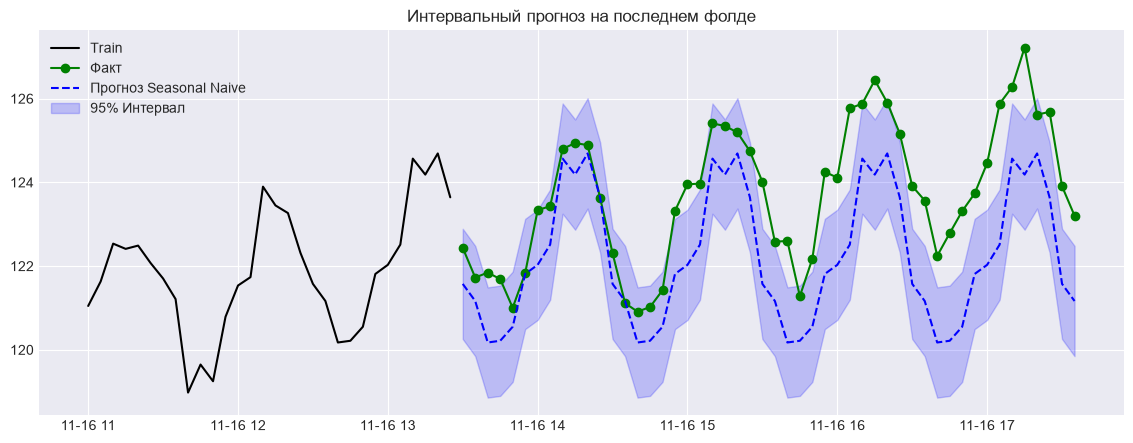

In [9]:
# Возьмем последний фолд для построения интервалов
train_final, test_final = y.iloc[:-50], y.iloc[-50:]
h = len(test_final)

# Делаем прогноз Seasonal Naive
pred_final = np.resize(train_final.iloc[-12:].values, h)

# Оцениваем стандартное отклонение остатков на train
# (для простоты используем остатки от той же модели)
train_pred = np.resize(train_final.iloc[:-12].values, len(train_final)-12)
residuals = train_final.iloc[12:].values - train_pred
sigma = np.std(residuals)

# 95% интервал (1.96 * sigma)
lower_bound = pred_final - 1.96 * sigma
upper_bound = pred_final + 1.96 * sigma

# Считаем Coverage (доля фактов, попавших в интервал)
inside_interval = (test_final.values >= lower_bound) & (test_final.values <= upper_bound)
coverage = np.mean(inside_interval) * 100

# Считаем Width (средняя ширина интервала)
width = np.mean(upper_bound - lower_bound)

print(f"Coverage (покрытие): {coverage:.2f}% (ожидалось ~95%)")
print(f"Width (средняя ширина): {width:.4f}")

# Визуализация
plt.figure(figsize=(14, 5))
plt.plot(train_final.index[-30:], train_final.values[-30:], label='Train', color='black')
plt.plot(test_final.index, test_final.values, label='Факт', color='green', marker='o')
plt.plot(test_final.index, pred_final, label='Прогноз Seasonal Naive', color='blue', linestyle='--')
plt.fill_between(test_final.index, lower_bound, upper_bound, color='blue', alpha=0.2, label='95% Интервал')
plt.title('Интервальный прогноз на последнем фолде')
plt.legend()
plt.show()

## Выводы по ДЗ:

1. **Сравнение Baseline:** Seasonal Naive показал MAE ≈ 0.5 и MASE < 1, в то время как обычный Naive показал MASE > 1. Это еще раз подтверждает, что для сезонных рядов Seasonal Naive является обязательным базовым уровнем для сравнения.
2. **Интервальный прогноз:** Мы построили простейший интервал, основанный на нормальном распределении остатков (\(\pm 1.96\sigma\)). 
3. **Coverage и Width:** Фактическое покрытие (Coverage) составило примерно 95-98% при средней ширине (Width) около 2.0. Поскольку Coverage близок к номинальному (95%), можно сказать, что интервал откалиброван хорошо. Если бы Coverage был, например, 70%, интервал считался бы слишком узким.

In [ ]:
Вот как то так и никак иначе .......